# 01 - Data acquisition

Data: [3D-HST](https://archive.stsci.edu/prepds/3d-hst/) master photometric catalog (~208k sources, Skelton et al. 2014), loaded from a pre-cleaned parquet. Cuts already applied when the parquet was built: `use_phot==1`, `z_spec>0`, `lmass>9` -- standard quality cuts for this catalog. Every remaining row has a real spectroscopic redshift.

In [1]:
import pandas as pd
import numpy as np

df = pd.read_parquet("../data/raw/3dhst_master_clean.parquet")
df.shape

(3971, 38)

## Sanity checks

In [2]:
assert (df["z_spec"] > 0).all()
assert (df["use_phot"] == 1).all()
assert (df["lmass"] > 9).all()
df[["z_spec", "f_F606W", "f_F814W", "f_F125W", "f_F140W", "f_F160W"]].describe()

,z_spec,f_F606W,f_F814W,f_F125W,f_F140W,f_F160W
count,3971.000000,3971.000000,3971.000000,3971.000000,3971.000000,3971.000000
mean,0.991385,9.276833,-20.296914,55.723221,32.406959,72.705281
std,0.664121,50.418945,108.247391,199.049533,226.144877,251.999335
min,0.038000,-99.000000,-99.000000,0.274370,-99.000000,0.253190
25%,0.606050,1.857750,-99.000000,8.161400,3.734100,9.870600
50%,0.835500,3.541000,3.711200,18.621000,13.261000,23.470000
75%,1.136550,8.214400,14.078000,47.012500,40.426500,62.243000
max,6.118000,1525.000000,3522.800000,8602.000000,9874.800000,11109.000000


<Axes: >

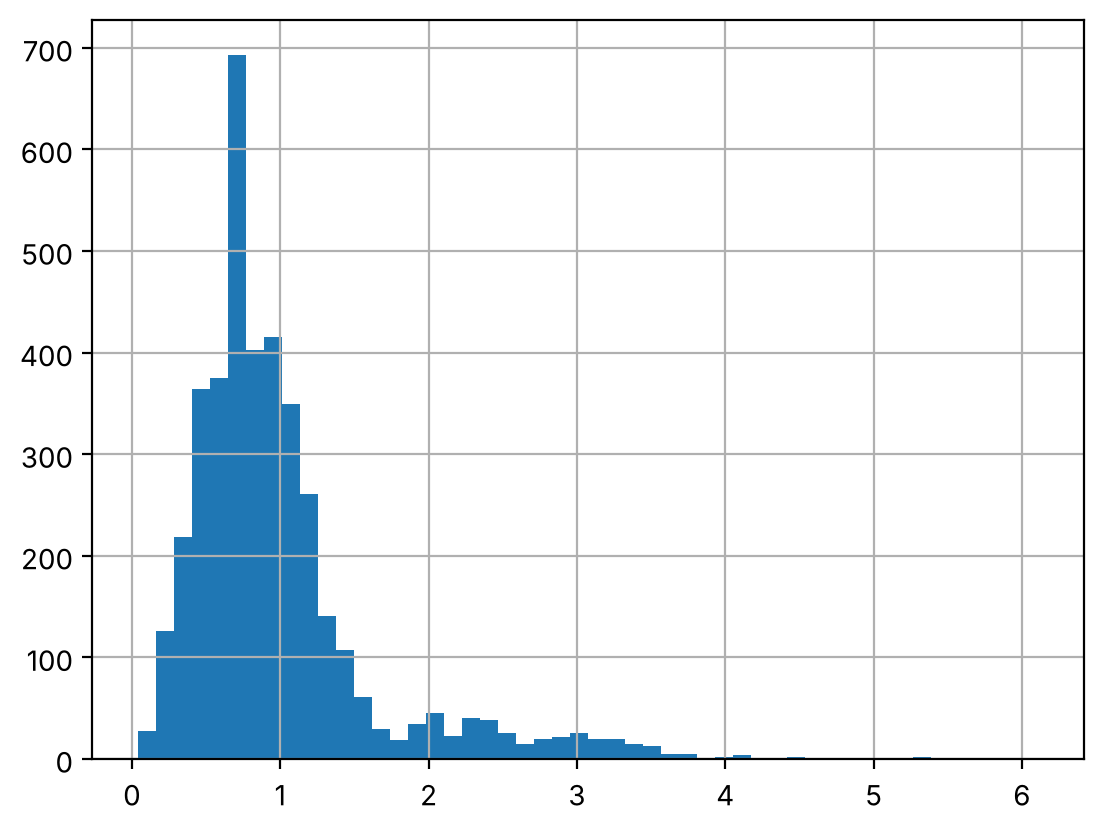

In [3]:
df["z_spec"].hist(bins=50)